# TP - Construire et entraîner un MLP avec TensorFlow/Keras

Ce TP applique le cours avec les fonctions prédéfinies de Keras. Vous construisez le réseau, choisissez ses réglages, lancez l’apprentissage et interprétez les résultats. TensorFlow calcule les gradients automatiquement. Un petit MLP NumPy est fourni au début pour lire son fonctionnement interne. Les exercices d’entraînement utilisent ensuite Keras, sans écriture ni dérivation des gradients.

**Objectifs :** utiliser `Sequential`, `Dense`, `compile`, `fit`, `predict` et `evaluate`, puis appliquer les activations, les optimisateurs, les lots, la régularisation et l’arrêt précoce. Vous sauvegarderez aussi un modèle utilisable dans une application.

**À rendre :** ce notebook complété, avec ses sorties, les réponses Q1-Q14 et le petit travail autonome final. Exécuter les cellules dans l’ordre. Les cellules « À COMPLÉTER » doivent être complétées avant de retirer leur `raise NotImplementedError`. Le notebook ne nécessite aucun fichier Python externe.


## Préparation de l’environnement
Ouvrir le notebook dans Google Colab ou Jupyter. Dans Colab, vérifier d’abord les imports. En local, si une bibliothèque manque, exécuter `%pip install tensorflow numpy matplotlib scikit-learn pandas`, puis redémarrer le kernel si nécessaire.

Les images viennent du jeu `digits` inclus dans scikit-learn. Aucun téléchargement d’images n’est nécessaire après installation. Le TP fonctionne sur CPU. La dernière partie charge un autre dataset depuis une URL publique, avec pandas. Exécuter la cellule suivante et relever les versions utilisées.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from ucimlrepo import fetch_ucirepo

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow :", tf.__version__, "Keras :", keras.__version__)
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

TensorFlow : 2.21.0 Keras : 3.15.1


## Lecture d’un petit MLP NumPy : ce qui se passe à l’intérieur

Le premier code est **entièrement fourni**. Il reprend XNOR sur les quatre couples binaires avec un réseau 2-3-1. Exécuter la cellule, lire les commentaires et observer les probabilités avant et après apprentissage. Il n’est pas demandé d’écrire ni de dériver les gradients.

**Questions de lecture :**
- Où les entrées traversent-elles les deux couches ?
- Où le programme compare-t-il les prédictions aux cibles ?
- Quelles lignes transmettent l’erreur vers la couche cachée ?
- Quelles lignes changent effectivement les poids et biais ?
- Quelle différence entre les méthodes `forward` et `fit` ?

À partir de la partie suivante, l’entraînement sur les images utilise **les fonctions prédéfinies de Keras**, qui automatisent ces étapes. Les étudiants construisent et configurent les réseaux sans réimplémenter leur apprentissage.


x1 x2 | cible | probabilité initiale | finale | décision
[[0.         0.         1.         0.5        0.99907544 1.        ]
 [0.         1.         0.         0.41086294 0.00300052 0.        ]
 [1.         0.         0.         0.60371855 0.00306072 0.        ]
 [1.         1.         1.         0.52542099 0.99673409 1.        ]]


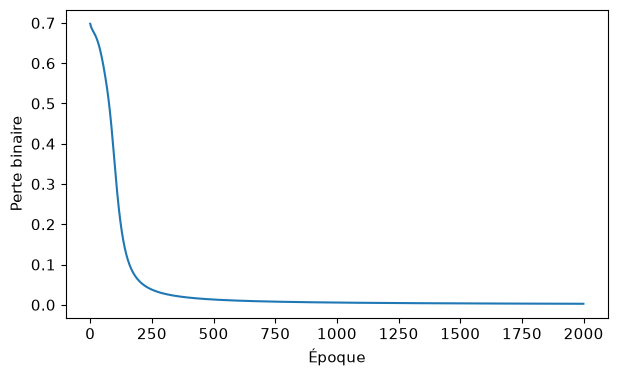

In [2]:
# Code fourni : exécuter et lire, sans le compléter.
class MiniMLP:
    def __init__(self, seed=5):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, 1/np.sqrt(2), (2, 3))
        self.b1 = np.zeros((1, 3))
        self.W2 = rng.normal(0, 1/np.sqrt(3), (3, 1))
        self.b2 = np.zeros((1, 1))

    def forward(self, X):
        # ÉTAPE 1 : propagation avant
        H = np.tanh(X @ self.W1 + self.b1)
        Z = H @ self.W2 + self.b2
        P = np.exp(-np.logaddexp(0, -Z))  # sigmoïde stable
        return H, Z, P

    def fit(self, X, y, epochs=2000, rate=0.5):
        losses = []
        for _ in range(epochs):
            H, Z, P = self.forward(X)
            # ÉTAPE 2 : mesure de l'erreur par la perte
            losses.append(float(np.mean(np.logaddexp(0, Z) - y*Z)))
            # ÉTAPE 3 : rétropropagation (formules déjà fournies)
            D2 = (P-y)/len(y)
            dW2 = H.T @ D2
            db2 = D2.sum(axis=0, keepdims=True)
            D1 = (D2 @ self.W2.T) * (1-H**2)
            dW1 = X.T @ D1
            db1 = D1.sum(axis=0, keepdims=True)
            # ÉTAPE 4 : mise à jour des paramètres
            self.W1 -= rate*dW1
            self.b1 -= rate*db1
            self.W2 -= rate*dW2
            self.b2 -= rate*db2
        return losses

X_logic = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y_logic = np.array([[1.],[0.],[0.],[1.]])
mini = MiniMLP()
initial_prob = mini.forward(X_logic)[2].copy()
logic_loss = mini.fit(X_logic, y_logic)
final_prob = mini.forward(X_logic)[2]
print("x1 x2 | cible | probabilité initiale | finale | décision")
print(np.column_stack([X_logic, y_logic, initial_prob, final_prob,
                      (final_prob >= 0.5).astype(int)]))
plt.plot(logic_loss)
plt.xlabel("Époque")
plt.ylabel("Perte binaire")
plt.show()
assert np.array_equal((final_prob >= 0.5).astype(int), y_logic.astype(int))


## 1. Charger et comprendre les données
Le jeu contient des images 8 × 8 de chiffres manuscrits de 0 à 9. Les intensités vont de 0 à 16. `data` donne déjà une représentation aplatie en 64 variables. `images` garde les images pour les afficher.

**Manipulation fournie :** charger le jeu et afficher dix observations. Les titres indiquent les cibles réelles.

**Q1.** Quel est le nombre d’observations et de variables ? Que représente une ligne de X ? S’agit-il d’une régression ou d’une classification ? Pourquoi les classes numériques ne sont-elles pas ici des valeurs continues ?


In [3]:
# --- Chargement (code donné par le prof) ---
dry_bean = fetch_ucirepo(id=602)
X_df = dry_bean.data.features
y_text = dry_bean.data.targets.values.ravel()
print("X :", X_df.shape, "| y :", y_text.shape)

# --- Variables d'entrée ---
print("\nVariables :", list(X_df.columns))

# --- Valeurs manquantes et doublons ---
print("\nValeurs manquantes :", X_df.isna().sum().sum())
data = X_df.copy()
data["Class"] = y_text
print("Doublons exacts :", data.duplicated().sum())

# --- Suppression des doublons AVANT la séparation ---
data = data.drop_duplicates().reset_index(drop=True)
print("Dimensions après suppression :", data.shape)

# --- Classes et effectifs ---
print("\nClasses et effectifs :")
print(data["Class"].value_counts())

# --- Échelles des variables ---
print("\nÉchelles (min / moyenne / max) :")
print(data.drop(columns="Class").describe().loc[["min", "mean", "max"]].round(3).T)

# --- Variables finales pour la suite du TP (mêmes noms que pour Digits) ---
X = data.drop(columns="Class").values.astype("float32")
y_text = data["Class"].values
feature_names = list(X_df.columns)
print("\nX final :", X.shape, "| y final :", y_text.shape)

X : (13611, 16) | y : (13611,)

Variables : ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Valeurs manquantes : 0
Doublons exacts : 68
Dimensions après suppression : (13543, 17)

Classes et effectifs :
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Échelles (min / moyenne / max) :
                       min       mean         max
Area             20420.000  53048.460  254616.000
Perimeter          524.736    854.993    1985.370
MajorAxisLength    183.601    319.896     738.860
MinorAxisLength    122.513    202.365     460.198
AspectRatio          1.025      1.581       2.430
Eccentricity         0.219      0.750       0.911
ConvexArea       20684.000  53767.987  263261.000
EquivDiameter      161.

## 2. Séparer et préparer les données
Garder environ 60 % pour l’entraînement, 20 % pour la validation et 20 % pour le test. La validation servira aux choix du modèle. Le test de digits reste de côté dans cette démonstration. Le travail autonome utilisera un nouveau dataset et son propre test final.

**À COMPLÉTER :** utiliser deux fois `train_test_split` : retirer 20 % pour le test, puis 25 % du reste pour la validation. Ajouter `stratify` et `random_state=SEED`. Ajuster `StandardScaler` seulement sur le train. Utiliser `transform` sur les deux autres ensembles.

**Indice :** `scaler.fit_transform(X_train)` apprend les statistiques et transforme le train. `scaler.transform(X_val)` réutilise ces mêmes statistiques.

**Q2.** Pourquoi conserver les proportions des classes ? Pourquoi ne pas ajuster le scaler sur toutes les images ? Quelle différence entre validation et test ?


In [4]:
# 1) 20 % pour le TEST (stratifié = mêmes proportions de variétés)
X_dev, X_test, y_dev_text, y_test_text = train_test_split(
    X, y_text, test_size=0.2, stratify=y_text, random_state=SEED)

# 2) 25 % du reste pour la VALIDATION -> environ 60 / 20 / 20
X_train, X_val, y_train_text, y_val_text = train_test_split(
    X_dev, y_dev_text, test_size=0.25, stratify=y_dev_text, random_state=SEED)

# 3) StandardScaler ajusté sur le TRAIN seulement
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # apprend moyenne/écart-type + transforme
X_val_s = scaler.transform(X_val)           # réutilise les mêmes statistiques
X_test_s = scaler.transform(X_test)

# 4) LabelEncoder : variétés (texte) -> numéros 0, 1, 2... (appris sur le train)
encoder = LabelEncoder()
y_train = encoder.fit_transform(y_train_text)
y_val = encoder.transform(y_val_text)
y_test = encoder.transform(y_test_text)

class_names = list(encoder.classes_)
n_features = X_train_s.shape[1]
n_classes = len(class_names)

print("Train / validation / test :", len(y_train), len(y_val), len(y_test))
print("Correspondance numéro -> variété :", dict(enumerate(class_names)))
print("Entrées :", n_features, "| Classes :", n_classes)
for nom, cible in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{nom:11}", np.bincount(cible))
assert np.allclose(scaler.mean_, X_train.mean(axis=0), rtol=1e-4)

Train / validation / test : 8125 2709 2709
Correspondance numéro -> variété : {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}
Entrées : 16 | Classes : 7
Train       [ 793  313  978 2127 1116 1216 1582]
Validation  [264 105 326 710 372 405 527]
Test        [265 104 326 709 372 406 527]


## 3. Définir le MLP avec `Sequential` et `Dense`
Créer un réseau qui reçoit 64 variables, utilise une couche cachée de 32 neurones avec ReLU et produit dix probabilités avec softmax.

- `keras.Sequential` empile les couches dans l’ordre.
- `keras.Input(shape=(64,))` décrit une observation, sans la dimension du lot.
- `Dense(32, activation="relu")` crée 32 neurones entièrement connectés.
- `Dense(10, activation="softmax")` produit une probabilité par classe.
- `summary()` affiche les couches et les paramètres.

**À COMPLÉTER :** construire le modèle puis afficher son résumé. Ne pas créer de classe Python personnalisée.

**Q3.** Combien de couches cachées ? Pourquoi dix sorties ? Combien de paramètres le résumé affiche-t-il ? Relier ce nombre aux poids et biais, sans calculer les gradients.


In [5]:
# Architecture 16 - 32 - 7
model = keras.Sequential([
    keras.Input(shape=(n_features,)),               # 16 mesures en entrée
    layers.Dense(32, activation="relu"),            # couche cachée : 32 neurones ReLU
    layers.Dense(n_classes, activation="softmax")   # sortie : 7 probabilités (une par variété)
])
model.summary()
print("Paramètres :", model.count_params())
assert model.count_params() == 775

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 775 (3.03 KB)

 Trainable params: 775 (3.03 KB)

 Non-trainable params: 0 (0.00 B)

Paramètres : 775


## 4. Configurer l’apprentissage avec `compile`
`compile` associe au modèle un optimisateur, une perte et des métriques. Ici : Adam, taux 0,001, `SparseCategoricalCrossentropy` et accuracy.

Le mot **sparse** signifie que les cibles sont des indices entiers, par exemple 3, et non des vecteurs one-hot. La sortie du réseau contient déjà softmax : garder `from_logits=False`, valeur par défaut. Ne pas appliquer une seconde sigmoïde ou softmax.

**À COMPLÉTER :** appeler `compile` avec l’optimisateur, la perte et la métrique indiqués.

**Q4.** Quelle différence entre la perte et l’accuracy ? Quelle combinaison sortie/perte utiliser pour une classification binaire ? Pour une régression non contrainte ?


In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),  # corrige les poids (pas = 0.001)
    loss=keras.losses.SparseCategoricalCrossentropy(),     # erreur multiclasse (cibles = numéros)
    metrics=["accuracy"])                                  # % de bonnes réponses

## 5. Entraîner avec `fit`
`fit` lance automatiquement la propagation, le calcul des gradients et la mise à jour des paramètres. Vous choisissez ses arguments, sans écrire ces opérations internes.

**À COMPLÉTER :** entraîner avec 40 époques maximum, lots de 32 et `validation_data=(X_val_s, y_val)`. Utiliser `verbose=0` pour garder le notebook lisible. Ici, pas d’arrêt précoce : toutes les époques demandées seront exécutées.

L’objet retourné est `History`. `history.history` contient notamment `loss`, `accuracy`, `val_loss` et `val_accuracy`.

**Q5.** Que représentent `epochs`, `batch_size` et `validation_data` ? Combien de lots pour 1077 observations avec une taille de 32 ? Les poids s’ajustent-ils à partir de la validation ?


In [7]:
history = model.fit(X_train_s, y_train,                 # apprend sur le train
                    epochs=40,                          # 40 passages sur toutes les données
                    batch_size=32,                      # mise à jour tous les 32 haricots
                    validation_data=(X_val_s, y_val),   # contrôle (n'ajuste pas les poids)
                    verbose=0)
print("Courbes disponibles :", list(history.history))
print("Époques exécutées :", len(history.history["loss"]))


Courbes disponibles : ['accuracy', 'loss', 'val_accuracy', 'val_loss']
Époques exécutées : 40


## 6. Lire les courbes d’apprentissage
Le code d’affichage est fourni. Observer le train et la validation simultanément. Les mesures train de `fit` sont accumulées pendant les mises à jour. La validation est mesurée à la fin de l’époque en mode évaluation : les deux courbes ne proviennent donc pas exactement du même instant.

**Q6.** La perte diminue-t-elle ? Les accuracies progressent-elles ? Un écart train/validation apparaît-il ? Décrire ce que montrent les courbes : une baisse de perte train ne garantit pas une amélioration de validation.



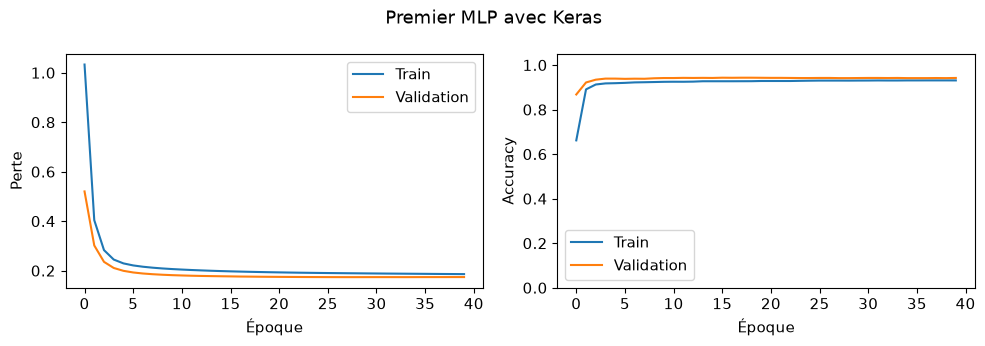

In [8]:
def plot_history(history, title):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="Train")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set(xlabel="Époque", ylabel="Perte")
    axes[1].plot(h["accuracy"], label="Train")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set(xlabel="Époque", ylabel="Accuracy", ylim=(0, 1.05))
    for ax in axes:
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Premier MLP avec Keras")

## 7. Prédire et évaluer sur validation
`predict` renvoie ici dix probabilités par image. `np.argmax(..., axis=1)` transforme ces probabilités en classes. `evaluate` renvoie la perte et les métriques configurées lors de `compile`.

**À COMPLÉTER :** prédire sur la validation, obtenir les classes et calculer la matrice de confusion. Utiliser `evaluate(..., return_dict=True)` pour lire les métriques par leur nom.

**Q7.** Quelle forme a le tableau de probabilités ? Pourquoi utiliser argmax plutôt qu’un seuil 0,5 ? Interpréter une confusion, la précision et le rappel d’une classe.


Évaluation : {'accuracy': 0.9420450329780579, 'loss': 0.17404629290103912}
Probabilités : (2709, 7)
              precision    recall  f1-score   support

    BARBUNYA      0.954     0.943     0.949       264
      BOMBAY      1.000     1.000     1.000       105
        CALI      0.939     0.951     0.945       326
    DERMASON      0.920     0.952     0.936       710
       HOROZ      0.967     0.960     0.964       372
       SEKER      0.965     0.965     0.965       405
        SIRA      0.921     0.880     0.900       527

    accuracy                          0.942      2709
   macro avg      0.952     0.950     0.951      2709
weighted avg      0.942     0.942     0.942      2709



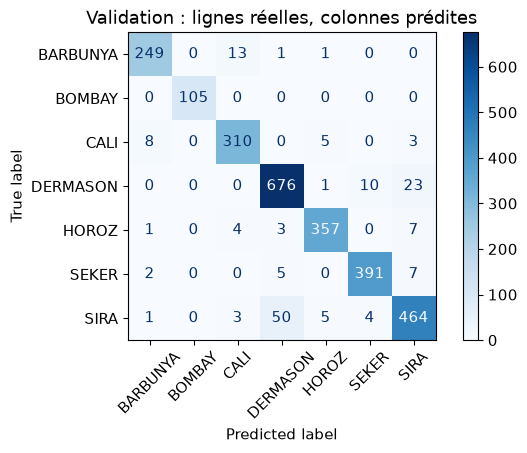

In [9]:
val_scores = model.evaluate(X_val_s, y_val, verbose=0, return_dict=True)  # perte + accuracy
prob_val = model.predict(X_val_s, verbose=0)    # 7 probabilités par haricot
pred_val = np.argmax(prob_val, axis=1)          # variété la plus probable

print("Évaluation :", val_scores)
print("Probabilités :", prob_val.shape)
assert np.allclose(prob_val.sum(axis=1), 1, atol=1e-5)   # softmax : somme = 1

# Précision, rappel, F1 pour chaque variété
print(classification_report(y_val, pred_val, target_names=class_names,
                            digits=3, zero_division=0))

# Matrice de confusion : lignes = vraie variété, colonnes = prédite
cm_val = confusion_matrix(y_val, pred_val, labels=np.arange(n_classes))
ConfusionMatrixDisplay(cm_val, display_labels=class_names).plot(
    cmap="Blues", xticks_rotation=45)
plt.title("Validation : lignes réelles, colonnes prédites")
plt.show()

## 8. Comparer des réglages avec des modèles neufs
La fonction fournie ci-dessous assemble uniquement des couches et fonctions Keras. Elle évite de recopier `Sequential` et `compile` pour chaque comparaison. Elle ne calcule ni gradients ni mises à jour manuellement.

La deuxième fonction prépare un résumé de validation. Sans pénalité, `evaluate` renvoie l’entropie croisée. Avec L1/L2, la perte évaluée inclut la pénalité. Pour comparer les variantes sur un critère commun, le résumé calcule aussi une **CE validation sans pénalité** avec la perte Keras prédéfinie.


In [10]:
def create_model(hidden=(32,), activation="relu", rate=0.001,
                 optimizer="adam", penalty=None, dropout=0.0, batchnorm=False,
                 input_dim=n_features, n_classes=n_classes):   # 16 entrées, 7 classes
    keras.utils.set_random_seed(SEED)                  # même départ pour chaque modèle
    net = keras.Sequential([keras.Input(shape=(input_dim,))])
    for units in hidden:                               # une couche cachée par valeur de hidden
        net.add(layers.Dense(units, kernel_regularizer=penalty))   # L1/L2 si demandé
        if batchnorm:
            net.add(layers.BatchNormalization())       # normalise les activations
        net.add(layers.Activation(activation))         # relu ou tanh
        if dropout > 0:
            net.add(layers.Dropout(dropout))           # éteint des neurones au hasard
    net.add(layers.Dense(n_classes, activation="softmax"))   # 7 probabilités
    opt = (keras.optimizers.Adam(learning_rate=rate) if optimizer == "adam"
           else keras.optimizers.SGD(learning_rate=rate))
    net.compile(optimizer=opt, loss="sparse_categorical_crossentropy",
                metrics=["accuracy"])
    return net

validation_loss = keras.losses.SparseCategoricalCrossentropy()

def summarize(name, net, hist):
    proba = net.predict(X_val_s, verbose=0)            # probabilités sur la validation
    pred = proba.argmax(axis=1)                        # variété prédite
    return {"modèle": name, "paramètres": net.count_params(),
            "époques": len(hist.history["loss"]),
            "CE_validation": float(validation_loss(y_val, proba).numpy()),  # perte sans pénalité
            "accuracy_validation": accuracy_score(y_val, pred),
            "F1_macro_validation": f1_score(y_val, pred, average="macro")}

### Taux d’apprentissage
**À COMPLÉTER :** avec `create_model(rate=eta)`, entraîner un réseau neuf pour chaque taux 0,0001, 0,001 et 0,05. Garder 30 époques et des lots de 32. Stocker le modèle et son historique dans `rate_runs`.

**Q8.** Quel taux avance lentement ? Le grand taux est-il instable dans cette expérience ? Expliquer à partir des courbes et des scores, sans supposer qu’un grand taux diverge toujours.


{'modèle': 'Adam, taux=0.0001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.2207067459821701, 'accuracy_validation': 0.9346622369878184, 'F1_macro_validation': 0.9447009499125466}
{'modèle': 'Adam, taux=0.001', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.17383438348770142, 'accuracy_validation': 0.9416758951642673, 'F1_macro_validation': 0.9504375365184458}
{'modèle': 'Adam, taux=0.05', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.2395826280117035, 'accuracy_validation': 0.9213732004429679, 'F1_macro_validation': 0.9342085969043963}


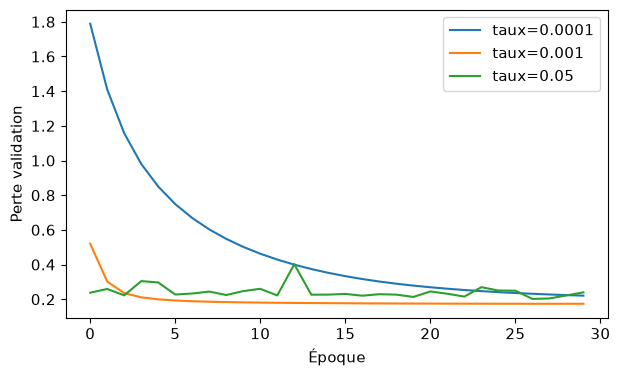

In [11]:
rate_runs = {}
for eta in [0.0001, 0.001, 0.05]:                  # 3 tailles de pas à comparer
    net = create_model(rate=eta)                   # modèle neuf pour chaque taux
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    rate_runs[eta] = (net, hist)
    print(summarize(f"Adam, taux={eta}", net, hist))
    plt.plot(hist.history["val_loss"], label=f"taux={eta}")   # une courbe par taux
plt.xlabel("Époque")
plt.ylabel("Perte validation")
plt.legend()
plt.show()

### Optimisateurs Adam et SGD
Le code fourni compare Adam et SGD sans momentum avec le même taux 0,001. Cette comparaison montre comment remplacer un optimisateur. Un même taux n’est pas forcément adapté aux deux algorithmes.

**Q9.** Quel appel Keras change ? Peut-on conclure qu’un optimisateur est toujours meilleur à partir de ce seul essai ? Quel paramètre faudrait-il aussi régler pour une comparaison plus pertinente ?


In [12]:
optimizer_runs = {}
for opt in ["adam", "sgd"]:                          # 2 optimiseurs, même taux
    net = create_model(rate=0.001, optimizer=opt)    # modèle neuf
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    optimizer_runs[opt] = (net, hist)
    print(summarize(opt, net, hist))

{'modèle': 'adam', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.17383438348770142, 'accuracy_validation': 0.9416758951642673, 'F1_macro_validation': 0.9504375365184458}
{'modèle': 'sgd', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.45666250586509705, 'accuracy_validation': 0.8955334071613141, 'F1_macro_validation': 0.9104125967067326}


### Tailles des lots
Le code fourni compare un exemple, un mini-lot de 32 et un lot complet. Le modèle utilise SGD avec un taux 0,01. Garder dix époques pour chaque essai.

**Q10.** Combien de mises à jour par époque pour les trois cas ? Pourquoi le même nombre d’époques ne signifie-t-il pas le même nombre de mises à jour ?


In [14]:
batch_runs = {}
for size in [1, 32, len(y_train)]:                   # SGD pur / mini-batch / batch complet
    net = create_model(rate=0.01, optimizer="sgd")
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=10, batch_size=size, verbose=0)
    batch_runs[size] = (net, hist)
    print(summarize(f"SGD, lot={size}", net, hist))
    # mises à jour par époque = taille du train / taille du lot
    print("Mises à jour par époque :", int(np.ceil(len(y_train) / size)))

{'modèle': 'SGD, lot=1', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.17865750193595886, 'accuracy_validation': 0.9394610557401255, 'F1_macro_validation': 0.9495319037983921}
Mises à jour par époque : 8125
{'modèle': 'SGD, lot=32', 'paramètres': 775, 'époques': 10, 'CE_validation': 0.2420877367258072, 'accuracy_validation': 0.932078257659653, 'F1_macro_validation': 0.9418374696239391}
Mises à jour par époque : 254
{'modèle': 'SGD, lot=8125', 'paramètres': 775, 'époques': 10, 'CE_validation': 2.1479334831237793, 'accuracy_validation': 0.022886674049464747, 'F1_macro_validation': 0.019080002286750504}
Mises à jour par époque : 1


### Couches cachées et activations
Le code fourni compare un réseau étroit, une référence, un réseau à deux couches cachées et une activation tanh. Les sorties restent softmax.

**Q11.** Repérer les changements de couches dans les configurations. Comparer les paramètres et les scores de validation. Un plus grand réseau améliore-t-il toujours la généralisation ?


In [15]:
architecture_runs = {}
for name, hidden, activation in [
        ("étroit", (2,), "relu"),           # 1 couche de 2 neurones : très petit réseau
        ("référence", (32,), "relu"),       # modèle de base : 1 couche de 32 neurones
        ("deux couches", (64, 32), "relu"), # réseau plus profond : 64 puis 32 neurones
        ("tanh", (32,), "tanh")]:           # même taille que la référence, autre activation
    net = create_model(hidden=hidden, activation=activation)   # modèle neuf
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=30, batch_size=32, verbose=0)
    architecture_runs[name] = (net, hist)
    print(summarize(name, net, hist))       # paramètres + scores sur la validation

{'modèle': 'étroit', 'paramètres': 55, 'époques': 30, 'CE_validation': 0.3667309284210205, 'accuracy_validation': 0.9099298634182356, 'F1_macro_validation': 0.9174757246101428}
{'modèle': 'référence', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.17383438348770142, 'accuracy_validation': 0.9416758951642673, 'F1_macro_validation': 0.9504375365184458}
{'modèle': 'deux couches', 'paramètres': 3399, 'époques': 30, 'CE_validation': 0.17716918885707855, 'accuracy_validation': 0.9398301956441492, 'F1_macro_validation': 0.9505721719167683}
{'modèle': 'tanh', 'paramètres': 775, 'époques': 30, 'CE_validation': 0.1758110076189041, 'accuracy_validation': 0.9420450350682908, 'F1_macro_validation': 0.9507041035622522}


## 9. Régulariser avec les couches et objets Keras
Les opérations prédéfinies évitent d’écrire les mécanismes internes :

- `keras.regularizers.l1(0.0001)` pénalise les poids via L1.
- `keras.regularizers.l2(0.001)` pénalise les poids via L2.
- `layers.Dropout(0.25)` masque aléatoirement une partie des activations pendant l’entraînement.
- `layers.BatchNormalization()` transforme les activations avec les statistiques du lot pendant l’entraînement, puis avec ses statistiques mobiles en évaluation.

Le code fourni active une seule option à la fois dans un MLP à deux couches cachées. Le même StandardScaler reste appliqué aux entrées. BatchNorm intervient à l’intérieur du réseau et ne remplace pas ce scaler.

**Q12.** Comparer les CE de validation sans pénalité. Pourquoi `evaluate` peut-il afficher une autre perte avec L1/L2 ? Quand Dropout est-il actif ? Pourquoi appeler `predict` ou `evaluate` pour une prédiction finale ? Une option améliore-t-elle systématiquement les résultats ?


{'modèle': 'référence', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17679177224636078, 'accuracy_validation': 0.94093761535622, 'F1_macro_validation': 0.9513206719439041}
Perte evaluate, pénalité éventuelle incluse : 0.17679160833358765
{'modèle': 'L1', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17416049540042877, 'accuracy_validation': 0.9413067552602437, 'F1_macro_validation': 0.9516395787546488}
Perte evaluate, pénalité éventuelle incluse : 0.2058373987674713
{'modèle': 'L2', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.1740785539150238, 'accuracy_validation': 0.9405684754521964, 'F1_macro_validation': 0.9504775314383958}
Perte evaluate, pénalité éventuelle incluse : 0.20429717004299164
{'modèle': 'Dropout', 'paramètres': 3399, 'époques': 35, 'CE_validation': 0.17965613305568695, 'accuracy_validation': 0.9413067552602437, 'F1_macro_validation': 0.9520084489868527}
Perte evaluate, pénalité éventuelle incluse : 0.17965592443943024
{'modèle': 'BatchNorm', 

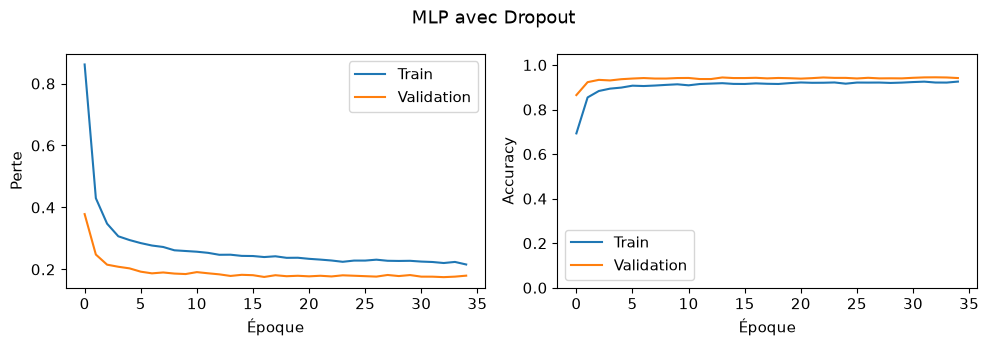

In [16]:
regularization_runs = {}
configs = [
    ("référence", {}),                                        # sans régularisation
    ("L1", {"penalty": keras.regularizers.l1(0.0001)}),       # pénalise la valeur absolue des poids
    ("L2", {"penalty": keras.regularizers.l2(0.001)}),        # pénalise le carré des poids
    ("Dropout", {"dropout": 0.25}),                           # éteint 25 % des neurones au hasard
    ("BatchNorm", {"batchnorm": True})                        # normalise les activations internes
]
for name, options in configs:
    net = create_model(hidden=(64, 32), **options)            # même réseau, une seule option à la fois
    hist = net.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                   epochs=35, batch_size=32, verbose=0)
    regularization_runs[name] = (net, hist)
    print(summarize(name, net, hist))                         # CE sans pénalité (comparable)
    print("Perte evaluate, pénalité éventuelle incluse :",    # CE + pénalité L1/L2
          net.evaluate(X_val_s, y_val, verbose=0, return_dict=True)["loss"])
plot_history(regularization_runs["Dropout"][1], "MLP avec Dropout")   # courbes du Dropout

In [17]:
probe = keras.Sequential([
    keras.Input(shape=(n_features,)),              # 16 entrées
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.5),                           # éteint 50 % des neurones (entraînement)
    layers.Dense(n_classes, activation="softmax")  # 7 sorties
])
eval1 = probe(X_val_s[:8], training=False).numpy()   # mode évaluation : Dropout inactif
eval2 = probe(X_val_s[:8], training=False).numpy()
train1 = probe(X_val_s[:8], training=True).numpy()   # mode entraînement : Dropout actif
train2 = probe(X_val_s[:8], training=True).numpy()
print("Évaluation identique :", np.allclose(eval1, eval2))      # attendu : True
print("Entraînement identique :", np.allclose(train1, train2))  # attendu : False

Évaluation identique : True
Entraînement identique : False


## 10. Arrêt précoce avec `EarlyStopping`
Keras peut arrêter l’apprentissage lorsque la perte de validation ne s’améliore plus. `patience=8` autorise huit époques sans amélioration. `restore_best_weights=True` restaure les meilleurs poids selon la perte suivie. Ici, `min_delta=0` rend le critère directement comparable au minimum de la courbe.

**À COMPLÉTER :** créer le callback, construire un réseau neuf, puis entraîner au maximum 100 époques en ajoutant `callbacks=[early_stop]` dans `fit`.

**Q13.** Combien d’époques ont été exécutées ? À quelle époque se situe la plus faible perte de validation ? Pourquoi ces nombres peuvent-ils différer ? L’arrêt est-il garanti avant le maximum ?


Époques exécutées : 36
Meilleure époque : 28
{'accuracy': 0.9413067698478699, 'loss': 0.1737634241580963}


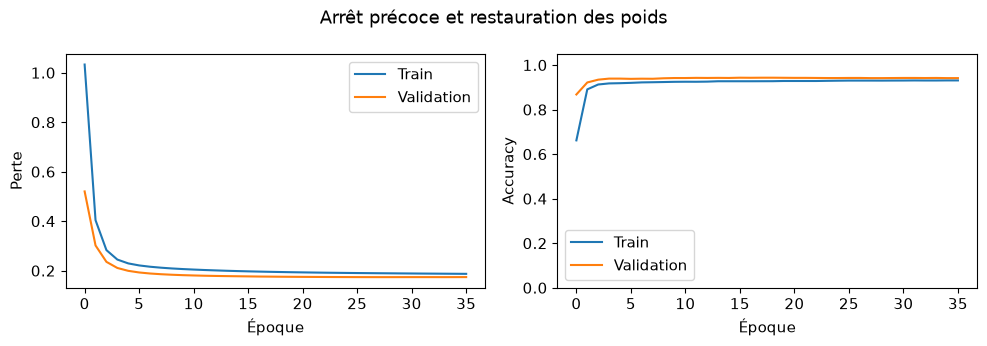

In [18]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",            # surveille la perte de validation
    patience=8,                    # 8 époques sans progrès -> arrêt
    min_delta=0,                   # toute baisse compte comme un progrès
    restore_best_weights=True)     # récupère les poids de la meilleure époque

early_model = create_model()       # modèle neuf (16-32-7)
early_history = early_model.fit(X_train_s, y_train,
                                validation_data=(X_val_s, y_val),
                                epochs=100, batch_size=32,      # 100 époques au maximum
                                callbacks=[early_stop], verbose=0)

print("Époques exécutées :", len(early_history.history["loss"]))
print("Meilleure époque :", 1 + np.argmin(early_history.history["val_loss"]))
print(early_model.evaluate(X_val_s, y_val, verbose=0, return_dict=True))   # scores finaux
plot_history(early_history, "Arrêt précoce et restauration des poids")

## 11. Sauvegarder et recharger le modèle
Cette manipulation illustre le passage d’une expérience à un composant d’application. Le format `.keras` conserve le modèle et ses poids. **Il ne conserve pas le StandardScaler de scikit-learn.** Une application devra sauvegarder aussi ce prétraitement et le réutiliser, jamais le réajuster sur chaque nouvelle entrée.

**À COMPLÉTER :** sauvegarder `early_model` avec `save("modele_mlp.keras")`, puis le recharger avec `keras.models.load_model`. Comparer les probabilités sur cinq images de validation déjà standardisées.

**Q14.** Pourquoi la sauvegarde du réseau seule ne suffit-elle pas pour servir des images brutes ? Quelle transformation appliquer avant predict ? En quoi predict diffère-t-il de fit ?


In [19]:
early_model.save("modele_drybean.keras")                         # sauvegarde réseau + poids
loaded_model = keras.models.load_model("modele_drybean.keras")   # rechargement depuis le fichier

# Le modèle rechargé doit donner exactement les mêmes prédictions
p_before = early_model.predict(X_val_s[:5], verbose=0)
p_after = loaded_model.predict(X_val_s[:5], verbose=0)
print("Prédictions conservées :", np.allclose(p_before, p_after, atol=1e-6))
assert np.allclose(p_before, p_after, atol=1e-6)

Prédictions conservées : True


## Documentation utile

- [Sequential et couches Dense](https://keras.io/guides/sequential_model/)
- [compile, fit, evaluate et predict](https://keras.io/guides/training_with_built_in_methods/)
- [EarlyStopping](https://keras.io/api/callbacks/early_stopping/)
- [Dropout](https://keras.io/api/layers/regularization_layers/dropout/)
- [BatchNormalization](https://keras.io/api/layers/normalization_layers/batch_normalization/)

Pour rendre le notebook reproductible, utiliser les mêmes ensembles et des modèles neufs pour chaque configuration. Des versions ou matériels différents peuvent produire des résultats légèrement différents malgré le seed.
